# 04 — Quanto contano i gruppi di testate parenti

I gruppi sono stati costruiti nel notebook 03 **senza guardare le etichette**. Solo adesso le usiamo, per misurare tre cose:

1. i gruppi hanno quasi sempre **un solo livello**? (se sì, riconoscere il gruppo basta per indovinare il livello)
2. il classificatore va meglio sulle testate che hanno **parenti nel training**?
3. quanto **scende** il risultato se separiamo i fold per gruppo invece che per testata?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from comune import (carica_dataset, classificatore_cv, per_testata, tabella_per_fold,
                    LIVELLI, DERIVED, RESULTS, SEED)

df = carica_dataset()
gruppi = pd.read_csv(RESULTS + "03_gruppi_testate.csv", index_col="domain")
art01 = pd.read_csv(RESULTS + "01_tfidf_predizioni_articoli.csv")
pub01 = pd.read_csv(RESULTS + "01_tfidf_predizioni_testate.csv").set_index("domain")

testate = pub01[["y_true", "fold"]].join(gruppi)
testate["in_gruppo"] = testate.testate_nel_gruppo >= 2
testate["giusta_01"] = pub01.y_true == pub01.y_pred
print(testate.in_gruppo.sum(), "testate in un gruppo,", (~testate.in_gruppo).sum(), "indipendenti")

236 testate in un gruppo, 203 indipendenti


## 1. I gruppi hanno un solo livello?

Per ogni gruppo contiamo le testate di ciascun livello.

In [2]:
composizione = pd.crosstab(testate[testate.in_gruppo].gruppo, testate[testate.in_gruppo].y_true.map(lambda k: LIVELLI[k]))
composizione["testate"] = composizione.sum(axis=1)
composizione.sort_values("testate", ascending=False)

y_true,l1,l2,l3,l4,l5,testate
gruppo,,,,,,
0,131,0,0,0,0,131
1,0,0,42,0,0,42
2,3,15,6,4,3,31
3,0,0,0,8,0,8
4,0,7,0,0,0,7
5,0,0,4,0,0,4
6,0,3,1,0,0,4
7,0,0,0,4,0,4
8,0,0,3,0,0,3


Misura semplice: per ogni testata in un gruppo, la quota dei suoi **compagni di gruppo con lo stesso livello**.
Poi la confrontiamo con quello che succederebbe **per caso**: rimescoliamo 1000 volte i livelli tra le testate,
lasciando i gruppi come sono, e ricalcoliamo la stessa quota.

In [3]:
def stesso_livello(livelli, gruppo):
    quote = []
    for g, membri in livelli.groupby(gruppo):
        if len(membri) < 2:
            continue
        conteggi = membri.value_counts()
        for liv in membri:
            quote.append((conteggi[liv] - 1) / (len(membri) - 1))
    return np.mean(quote)

osservato = stesso_livello(testate.y_true, testate.gruppo)
rng = np.random.default_rng(SEED)
per_caso = [stesso_livello(pd.Series(rng.permutation(testate.y_true.values), index=testate.index), testate.gruppo)
            for _ in range(1000)]

print(f"compagni di gruppo con lo stesso livello: {osservato:.0%}")
print(f"per caso: in media {np.mean(per_caso):.0%}, al massimo {np.max(per_caso):.0%} in 1000 prove")

compagni di gruppo con lo stesso livello: 90%
per caso: in media 24%, al massimo 28% in 1000 prove


## 2. Il classificatore va meglio nei gruppi?

Accuratezza per testata del notebook 01 (separazione per testata, come nel paper), divisa tra testate
in un gruppo e testate indipendenti.

In [4]:
acc = testate.groupby(["y_true", "in_gruppo"]).giusta_01.agg(["mean", "size"]).unstack()
acc.columns = [f"{'accuratezza' if m == 'mean' else 'testate'} {'nei gruppi' if g else 'indipendenti'}" for m, g in acc.columns]
acc = acc.rename(index=lambda k: LIVELLI[k])
acc.loc["tutte"] = [testate[testate.in_gruppo == False].giusta_01.mean(), testate[testate.in_gruppo].giusta_01.mean(),
                    (~testate.in_gruppo).sum(), testate.in_gruppo.sum()]
acc.round(3)

,accuratezza indipendenti,accuratezza nei gruppi,testate indipendenti,testate nei gruppi
y_true,,,,
l1,0.278,0.970,18.0,134.0
l2,0.714,0.889,42.0,27.0
l3,0.205,0.875,39.0,56.0
l4,0.542,0.750,72.0,16.0
l5,0.062,0.000,32.0,3.0
tutte,0.414,0.911,203.0,236.0


## 3. Accuratezza in base alla parentela con il training

Per ogni testata del test misuriamo **quanto è parente del training**: la quota dei suoi articoli che hanno
una copia quasi uguale in una testata del training (cioè degli altri fold). Poi guardiamo l'accuratezza per fasce.
Se sale con la parentela, il classificatore sta riconoscendo le testate sorelle.

,accuratezza,testate
parentela,,
0,0.420,181
fino al 25%,0.577,71
25-50%,0.968,63
50-75%,0.949,39
oltre 75%,0.988,85


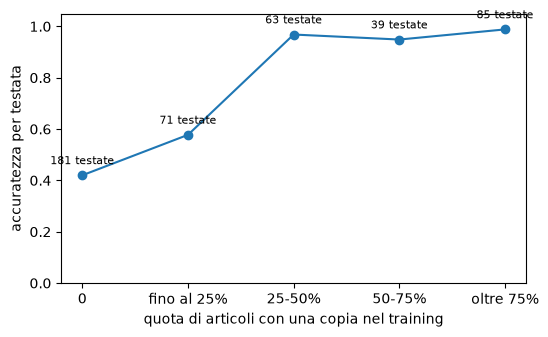

In [5]:
coppie = pd.read_csv(DERIVED + "03_coppie_quasi_uguali.csv.gz")
fold_testata = testate.fold
coppie["fold_a"], coppie["fold_b"] = coppie.testata_a.map(fold_testata), coppie.testata_b.map(fold_testata)
diverse = coppie[coppie.fold_a != coppie.fold_b]   # una delle due testate è nel training dell'altra
con_copia_nel_training = pd.concat([diverse[["articolo_a", "testata_a"]].set_axis(["articolo", "testata"], axis=1),
                                    diverse[["articolo_b", "testata_b"]].set_axis(["articolo", "testata"], axis=1)]).drop_duplicates()
articoli_per_testata = df.domain.value_counts()
testate["parentela"] = (con_copia_nel_training.testata.value_counts() / articoli_per_testata).reindex(testate.index).fillna(0)

fasce = pd.cut(testate.parentela, [-0.01, 0, 0.25, 0.5, 0.75, 1.0], labels=["0", "fino al 25%", "25-50%", "50-75%", "oltre 75%"])
curva = testate.groupby(fasce, observed=True).giusta_01.agg(accuratezza="mean", testate="size")
display(curva.round(3))

plt.figure(figsize=(6, 3.5))
plt.plot(curva.index.astype(str), curva.accuratezza, marker="o")
for x, (a, n) in enumerate(zip(curva.accuratezza, curva.testate)):
    plt.annotate(f"{n} testate", (x, a), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.ylim(0, 1.05)
plt.xlabel("quota di articoli con una copia nel training")
plt.ylabel("accuratezza per testata")
plt.show()

## 4. Separare i fold per gruppo

Ora rifacciamo la valutazione con una regola più severa: **ogni gruppo sta tutto in un solo fold**,
così nessuna testata ha sorelle nel training. Le testate indipendenti restano distribuite come prima,
mantenendo nei fold proporzioni di livelli simili (`StratifiedGroupKFold`, seed 42).

In [6]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
testate["fold_gruppo"] = 0
for fold, (_, idx) in enumerate(sgkf.split(testate.index, testate.y_true, groups=testate.gruppo), start=1):
    testate.iloc[idx, testate.columns.get_loc("fold_gruppo")] = fold

pd.crosstab(testate.fold_gruppo, testate.y_true.map(lambda k: LIVELLI[k]), margins=True, margins_name="totale")

y_true,l1,l2,l3,l4,l5,totale
fold_gruppo,,,,,,
1,5,13,42,17,7,84
2,5,15,13,18,7,58
3,131,13,13,17,7,181
4,5,14,13,18,7,57
5,6,14,14,18,7,59
totale,152,69,95,88,35,439


Attenzione: il gruppo più grande (131 testate $l_1$) finisce tutto in un fold. Quando quel fold è il test,
nel training restano poche testate $l_1$: una parte del calo su $l_1$ dipende anche da questo, non solo dalle sorelle.

In [7]:
df["fold_gruppo"] = df.domain.map(testate.fold_gruppo)
df["pred_gruppo"] = classificatore_cv(df, colonna_fold="fold_gruppo")

art_g = df.rename(columns={"label": "y_true", "pred_gruppo": "y_pred", "fold_gruppo": "fold"})[["domain", "fold", "y_true", "y_pred"]]
pub_g = per_testata(art_g).set_index("domain")
testate["giusta_gruppo"] = pub_g.y_true == pub_g.y_pred

confronto = pd.DataFrame({
    "per testata (paper)": tabella_per_fold(art01).loc["media"],
    "per gruppo": tabella_per_fold(art_g).loc["media"]})
confronto_pub = pd.DataFrame({
    "per testata (paper)": tabella_per_fold(pub01.reset_index()).loc["media"],
    "per gruppo": tabella_per_fold(pub_g.reset_index()).loc["media"]})
print("PER ARTICOLO (media sui fold)"); display(confronto)
print("PER TESTATA (media sui fold)"); display(confronto_pub)

PER ARTICOLO (media sui fold)


,per testata (paper),per gruppo
Accuracy,0.576,0.409
F1 macro,0.521,0.315
Tolerant α=0.5,0.696,0.554
Tolerant α=1.0,0.816,0.699


PER TESTATA (media sui fold)


,per testata (paper),per gruppo
Accuracy,0.681,0.437
F1 macro,0.564,0.369
Tolerant α=0.5,0.780,0.563
Tolerant α=1.0,0.879,0.688


Accuratezza per testata, livello per livello, separando tra testate nei gruppi e indipendenti:

In [8]:
righe = []
for (liv, ing), g in testate.groupby(["y_true", "in_gruppo"]):
    righe.append({"livello": LIVELLI[liv], "testate": "nei gruppi" if ing else "indipendenti", "n": len(g),
                  "per testata (paper)": g.giusta_01.mean(), "per gruppo": g.giusta_gruppo.mean()})
for ing, g in testate.groupby("in_gruppo"):
    righe.append({"livello": "tutti", "testate": "nei gruppi" if ing else "indipendenti", "n": len(g),
                  "per testata (paper)": g.giusta_01.mean(), "per gruppo": g.giusta_gruppo.mean()})
pd.DataFrame(righe).set_index(["livello", "testate"]).round(3)

n  per testata (paper)  per gruppo
livello testate                                           
l1      indipendenti   18                0.278       0.222
        nei gruppi    134                0.970       0.127
l2      indipendenti   42                0.714       0.690
        nei gruppi     27                0.889       0.630
l3      indipendenti   39                0.205       0.256
        nei gruppi     56                0.875       0.875
l4      indipendenti   72                0.542       0.542
        nei gruppi     16                0.750       0.188
l5      indipendenti   32                0.062       0.156
        nei gruppi      3                0.000       0.000
tutti   indipendenti  203                0.414       0.429
        nei gruppi    236                0.911       0.364

## 5. Salvataggio

In [9]:
testate[["y_true", "gruppo", "in_gruppo", "parentela", "fold", "fold_gruppo", "giusta_01", "giusta_gruppo"]].to_csv(RESULTS + "04_testate_gruppi_valutazione.csv")
art_g.to_csv(RESULTS + "04_tfidf_predizioni_articoli_fold_per_gruppo.csv", index=False)
print("Salvato.")

Salvato.
